# Exploring the OMI house price data

The **Osservatorio del Mercato Immobiliare** (OMI, part of the Agenzia delle Entrate)
divides every comune into **zones** with similar prices and, every six months,
publishes a **price range** (min-max €/m²) to buy and to rent, for each zone and
type of property. We have two semesters: **2014 H2** and **2024 H2**.

1. Unzip and find the files
2. Read them (the format needs some care)
3. Understand the data: what is one row?
4. From zones to one price per comune
5. Insights:
   - 5.1 Where are homes expensive? (comuni and regions)
   - 5.2 Centre vs periphery: how unequal are prices inside a city?
   - 5.3 Prices 2014 → 2024: where did they rise, where did they fall?
   - 5.4 Buy or rent? Rental yield and price-to-rent ratio
   - 5.5 First look at the main question: years of income to buy a home

⚠️ I wrote this notebook without seeing your files. Cells marked **CHECK** print
something you should look at before trusting the next cells.

In [26]:
import re
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# The notebook runs from notebooks/, so the project root is one level up
base_dir = Path.cwd().parent
omi_raw_dir = base_dir / "data" / "raw" / "omi"
mef_raw_dir = base_dir / "data" / "raw" / "mef"

FLAT_SIZE_M2 = 70        # size of the "typical flat" used in the insights
MIN_TAXPAYERS = 1000     # same rule as the MEF notebook: rankings only for bigger comuni
MILAN_CODE = "015146"

## 1. Unzip and find the files

Each ZIP you downloaded contains (at least) two CSV files:
- **VALORI**: the prices and rents
- **ZONE**: the description of each zone (centre, periphery, ...)

We extract every ZIP into its own folder, so files of different semesters never mix.

In [27]:
for zip_path in sorted(omi_raw_dir.glob("*.zip")):
    target_dir = omi_raw_dir / zip_path.stem          # same name as the ZIP, without .zip
    if target_dir.exists():
        print(f"{zip_path.name}: already extracted")
        continue
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(target_dir)
    print(f"{zip_path.name}: extracted to {target_dir.relative_to(base_dir)}")

# CHECK: what is inside? (rglob = search in all sub-folders)
for path in sorted(omi_raw_dir.rglob("*")):
    if path.is_file() and path.suffix.lower() != ".zip":
        print(path.relative_to(omi_raw_dir), f"({path.stat().st_size / 1e6:.1f} MB)")

omi_2014_2.zip: already extracted
omi_2024_2.zip: already extracted
.DS_Store (0.0 MB)
omi_2014_2/QI_1458638_1_20142_VALORI.csv (18.9 MB)
omi_2014_2/QI_1458638_1_20142_ZONE.csv (3.6 MB)
omi_2024_2/QI_1458639_1_20242_VALORI.csv (18.3 MB)
omi_2024_2/QI_1458639_1_20242_ZONE.csv (3.5 MB)


### Which file belongs to which semester?
OMI file names contain the semester as `YYYYS`, e.g. `20242` = 2024, 2nd semester.
We read it from the name with a **regular expression** and check that we find
exactly one VALORI and one ZONE file per semester.

In [ ]:
def find_semester(filename):
    """
    Read the semester from an OMI file name.

    Parameters
    ----------
    filename : str
        For example ``"QI_1234_1_20242_VALORI.csv"``.

    Returns
    -------
    str or None
        ``"2024_2"`` for the example above, or ``None`` if no semester is found.
    """
    # (20\d\d) = a year 2000-2099, ([12]) = semester 1 or 2, \D = not followed by a digit
    match = re.search(r"(20\d\d)([12])(?:\D|$)", filename)
    return f"{match.group(1)}_{match.group(2)}" if match else None


omi_files = {}   # {"2024_2": {"VALORI": path, "ZONE": path}, ...}
for path in sorted(omi_raw_dir.rglob("*.csv")):
    kind = "VALORI" if "VALORI" in path.name.upper() else "ZONE" if "ZONE" in path.name.upper() else None
    semester = find_semester(path.name)
    print(f"{path.name:<45} -> semester {semester}, kind {kind}")
    if kind and semester:
        omi_files.setdefault(semester, {})[kind] = path  #it creates a semester: {} and the output it {}. so [kind] = path with add to {}.

print("\nFound:", {sem: sorted(kinds) for sem, kinds in omi_files.items()})
# If the semester is None for your files, write the mapping by hand instead, e.g.:
# omi_files = {"2014_2": {"VALORI": omi_raw_dir / "...", "ZONE": omi_raw_dir / "..."}, ...}

QI_1458638_1_20142_VALORI.csv                 -> semester 2014_2, kind VALORI
QI_1458638_1_20142_ZONE.csv                   -> semester 2014_2, kind ZONE
QI_1458639_1_20242_VALORI.csv                 -> semester 2024_2, kind VALORI
QI_1458639_1_20242_ZONE.csv                   -> semester 2024_2, kind ZONE

Found: {'2014_2': ['VALORI', 'ZONE'], '2024_2': ['VALORI', 'ZONE']}


## 2. Read the files

OMI CSVs usually have a **title line above the header** (e.g. "Quotazioni ... 2024/2"),
use `;` as separator and end every line with `;` (which creates an empty column,
like the MEF files). Instead of guessing `skiprows`, we look for the line that
contains the column names.

In [29]:
# CHECK: the first lines of one file, exactly as they are on disk
first_valori = next(iter(omi_files.values()))["VALORI"]
with open(first_valori, encoding="latin-1") as f:
    for _ in range(4):
        print(repr(f.readline()[:200]))

'Quotazioni Immobiliari : Valori di Mercato - Semestre 2014/2 - elaborazione del 27-OTT-26\n'
'Area_territoriale;Regione;Prov;Comune_ISTAT;Comune_cat;Sez;Comune_amm;Comune_descrizione;Fascia;Zona;LinkZona;Cod_Tip;Descr_Tipologia;Stato;Stato_prev;Compr_min;Compr_max;Sup_NL_compr;Loc_min;Loc_max;'
'NORD-OVEST;PIEMONTE;AL;1006003;A2AA; ;A182;ALESSANDRIA;B;B1;AL00000001;20;Abitazioni civili;NORMALE;P;760;980;L;3,6;4,7;L;\n'
'NORD-OVEST;PIEMONTE;AL;1006003;A2AA; ;A182;ALESSANDRIA;B;B1;AL00000001;13;Box;NORMALE;P;1100;1600;L;4,4;6,2;L;\n'


In [ ]:
def find_header_row(path, marker="Zona", max_lines=10):
    """
    Find the line number where the column names are.

    Parameters
    ----------
    path : pathlib.Path
        The CSV file.
    marker : str, optional
        A column name that appears in the header line.
    max_lines : int, optional
        How many lines to look at.

    Returns
    -------
    int
        The 0-based number of the header line (use it as ``skiprows``).

    Raises
    ------
    ValueError
        If the marker is not found in the first ``max_lines`` lines.
    """
    with open(path, encoding="latin-1") as f:
        for number, line in enumerate(f):
            if number >= max_lines:
                break
            if marker in line.split(";"):
                return number
    raise ValueError(f"No header with '{marker}' in the first {max_lines} lines of {path.name}")


def read_omi_csv(path):
    """
    Read one OMI CSV (VALORI or ZONE) into a DataFrame.

    Parameters
    ----------
    path : pathlib.Path
        The CSV file.

    Returns
    -------
    pandas.DataFrame
        All columns as text (we convert the numbers ourselves), without empty
        columns and with stripped column names.
    """
    df = pd.read_csv(
        path,
        sep=";",
        encoding="latin-1",
        skiprows=find_header_row(path),
        dtype=str,                 # read everything as text: codes keep their zeros
        keep_default_na=False,     # "NA" (Napoli) stays text
        na_values=[""],
    )
    df.columns = [col.strip() for col in df.columns]
    return df.dropna(axis=1, how="all")   # drop the empty column made by the final ";"


raw = {sem: {kind: read_omi_csv(path) for kind, path in kinds.items()} for sem, kinds in omi_files.items()}

for sem, tables in raw.items():
    for kind, df in tables.items():
        print(f"{sem} {kind}: {df.shape}")
        print("   columns:", df.columns.tolist())

2014_2 VALORI: (162756, 21)
   columns: ['Area_territoriale', 'Regione', 'Prov', 'Comune_ISTAT', 'Comune_cat', 'Sez', 'Comune_amm', 'Comune_descrizione', 'Fascia', 'Zona', 'LinkZona', 'Cod_Tip', 'Descr_Tipologia', 'Stato', 'Stato_prev', 'Compr_min', 'Compr_max', 'Sup_NL_compr', 'Loc_min', 'Loc_max', 'Sup_NL_loc']
2014_2 ZONE: (27484, 16)
   columns: ['Area_territoriale', 'Regione', 'Prov', 'Comune_ISTAT', 'Comune_cat', 'Sez', 'Comune_amm', 'Comune_descrizione', 'Fascia', 'Zona_Descr', 'Zona', 'LinkZona', 'Cod_tip_prev', 'Descr_tip_prev', 'Stato_prev', 'Microzona']
2024_2 VALORI: (157685, 21)
   columns: ['Area_territoriale', 'Regione', 'Prov', 'Comune_ISTAT', 'Comune_cat', 'Sez', 'Comune_amm', 'Comune_descrizione', 'Fascia', 'Zona', 'LinkZona', 'Cod_Tip', 'Descr_Tipologia', 'Stato', 'Stato_prev', 'Compr_min', 'Compr_max', 'Sup_NL_compr', 'Loc_min', 'Loc_max', 'Sup_NL_loc']
2024_2 ZONE: (26995, 16)
   columns: ['Area_territoriale', 'Regione', 'Prov', 'Comune_ISTAT', 'Comune_cat', 'Sez',

## 3. What is one row?

The columns we expect in **VALORI** (CHECK the names printed above):

| Column | Meaning |
|---|---|
| `Regione`, `Prov` | Region and province |
| `Comune_ISTAT` | ISTAT code of the comune: our join key |
| `Comune_descrizione` | Name of the comune |
| `Fascia` | Where the zone is: **B** centre, **C** semi-centre, **D** periphery, **E** suburban, **R** rural |
| `Zona` | Zone code inside the comune (B1, C2, D5, ...) |
| `Descr_Tipologia` | Property type: *Abitazioni civili*, *Box*, *Negozi*, *Uffici*, ... |
| `Stato` | Condition: *NORMALE*, *OTTIMO* (excellent), *SCADENTE* (poor) |
| `Compr_min`, `Compr_max` | Price to **buy**, €/m² |
| `Loc_min`, `Loc_max` | Price to **rent**, €/m² per month |

So one row = **one zone × one property type × one condition**. Milan has dozens
of zones and many types, so it has hundreds of rows; a village may have 2-3.

In [49]:
CODE_COL = "Comune_ISTAT"
NAME_COL = "Comune_descrizione"
REGION_COL = "Regione"
FASCIA_COL = "Fascia"
ZONE_COL = "Zona"
TYPE_COL = "Descr_Tipologia"
STATE_COL = "Stato"
PRICE_COLS = ["Compr_min", "Compr_max", "Loc_min", "Loc_max"]

valori_latest = raw["2024_2"]["VALORI"]
print(valori_latest[[CODE_COL, NAME_COL, FASCIA_COL, ZONE_COL, TYPE_COL, STATE_COL] + PRICE_COLS].head(10).to_string())

  Comune_ISTAT Comune_descrizione Fascia Zona      Descr_Tipologia    Stato Compr_min Compr_max Loc_min Loc_max
0      1006003        ALESSANDRIA      B   B1    Abitazioni civili  NORMALE       540       810     5,1     7,6
1      1006003        ALESSANDRIA      B   B1                  Box  NORMALE       680      1000       4     5,8
2      1006003        ALESSANDRIA      B   B1   Posti auto coperti  NORMALE       530       790     2,7     3,8
3      1006003        ALESSANDRIA      B   B1  Posti auto scoperti  NORMALE       430       640     2,5     3,3
4      1006003        ALESSANDRIA      B   B1            Magazzini  NORMALE       810      1150     4,6     5,4
5      1006003        ALESSANDRIA      B   B1               Negozi  NORMALE       450       900     6,4    12,2
6      1006003        ALESSANDRIA      B   B1               Uffici  NORMALE       380       760     3,6     7,2
7      1006003        ALESSANDRIA      B   B1           Laboratori  NORMALE      1350      1600     6,7 

In [51]:
# CHECK: which property types and conditions exist, and how many rows each
print(valori_latest[TYPE_COL].value_counts())
print()
print(valori_latest[STATE_COL].value_counts())
print()
print(valori_latest[FASCIA_COL].value_counts())

Descr_Tipologia
Abitazioni civili                26321
Ville e Villini                  18277
Abitazioni di tipo economico     17545
Box                              16678
Negozi                           16578
Magazzini                        14086
Uffici                           11526
Laboratori                       11413
Capannoni tipici                  8993
Capannoni industriali             5398
Autorimesse                       3804
Posti auto scoperti               2883
Posti auto coperti                2809
Centri commerciali                 472
Uffici strutturati                 338
Abitazioni tipiche dei luoghi      328
Abitazioni signorili               236
Name: count, dtype: int64

Stato
NORMALE     138537
OTTIMO       18477
SCADENTE       671
Name: count, dtype: int64

Fascia
B    64673
D    30634
R    27815
E    24015
C    10548
Name: count, dtype: int64


### Visualising what OMI contains
The counts above are **numbers of quotations** (one zone × type × condition), not numbers of houses. Two questions are worth a picture:
1. What is in the file, and which part do we keep? (highlighted in blue)
2. Does the price really change with the property type and the position in the city?

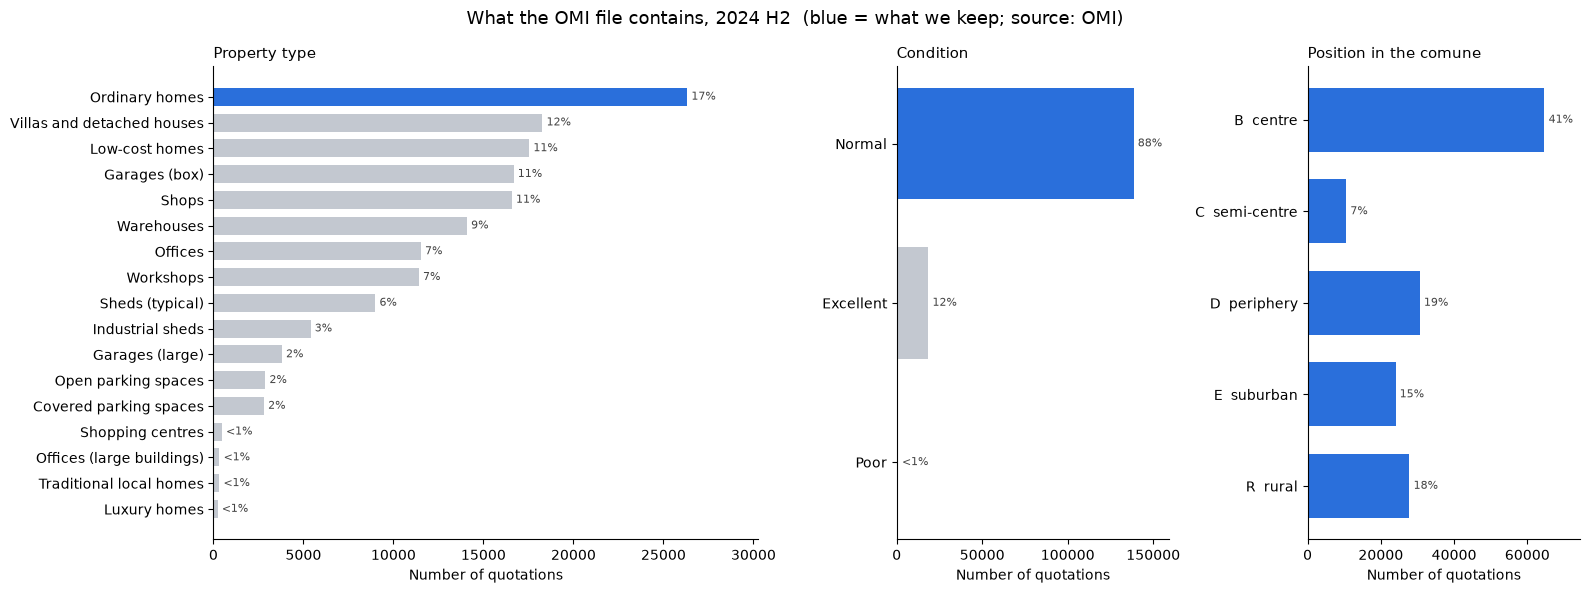

In [52]:
# English labels for the charts (the data keeps the Italian names)
TYPE_LABELS = {
    "Abitazioni civili": "Ordinary homes",
    "Abitazioni di tipo economico": "Low-cost homes",
    "Abitazioni signorili": "Luxury homes",
    "Abitazioni tipiche dei luoghi": "Traditional local homes",
    "Ville e Villini": "Villas and detached houses",
    "Box": "Garages (box)",
    "Autorimesse": "Garages (large)",
    "Posti auto coperti": "Covered parking spaces",
    "Posti auto scoperti": "Open parking spaces",
    "Negozi": "Shops",
    "Centri commerciali": "Shopping centres",
    "Uffici": "Offices",
    "Uffici strutturati": "Offices (large buildings)",
    "Magazzini": "Warehouses",
    "Laboratori": "Workshops",
    "Capannoni tipici": "Sheds (typical)",
    "Capannoni industriali": "Industrial sheds",
}
STATE_LABELS = {"NORMALE": "Normal", "OTTIMO": "Excellent", "SCADENTE": "Poor"}
FASCIA_LABELS = {"B": "B  centre", "C": "C  semi-centre", "D": "D  periphery",
                 "E": "E  suburban", "R": "R  rural"}
FASCIA_ORDER = ["B", "C", "D", "E", "R"]   # from the centre outwards, not by count

KEPT_COLOR = "#2a6fdb"     # the part of the data we use
OTHER_COLOR = "#c3c8d0"    # everything else


def plot_counts(ax, counts, labels, kept, title, sort=True):
    """
    Horizontal bar chart of counts, with the kept category highlighted.

    Parameters
    ----------
    ax : matplotlib.axes.Axes
        Where to draw.
    counts : pandas.Series
        Index = original category names, values = number of rows.
    labels : dict
        Original name -> label to show.
    kept : str or None
        The category we keep in the analysis (drawn in blue).
        ``None`` = we keep all categories, so every bar is blue.
    title : str
        Title of the panel.
    sort : bool, optional
        If True, biggest bar on top; if False, keep the order of ``counts``.
    """
    if sort:
        counts = counts.sort_values()
    else:
        counts = counts.iloc[::-1]          # barh draws from the bottom up
    colors = [KEPT_COLOR if kept is None or name == kept else OTHER_COLOR for name in counts.index]
    names = [labels.get(name, name) for name in counts.index]
    bars = ax.barh(names, counts.values, color=colors, height=0.7)
    # Percentage of all rows at the end of each bar
    shares = counts / counts.sum() * 100
    ax.bar_label(bars, labels=[f"{s:.0f}%" if s >= 1 else "<1%" for s in shares],
                 padding=3, fontsize=8, color="#444")
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("Number of quotations")
    ax.spines[["top", "right"]].set_visible(False)
    ax.margins(x=0.15)                      # room for the % labels


fig, axes = plt.subplots(1, 3, figsize=(16, 6), gridspec_kw={"width_ratios": [2, 1, 1]})
plot_counts(axes[0], valori_latest[TYPE_COL].value_counts(), TYPE_LABELS,
            "Abitazioni civili", "Property type")
plot_counts(axes[1], valori_latest[STATE_COL].value_counts(), STATE_LABELS,
            "NORMALE", "Condition")
plot_counts(axes[2], valori_latest[FASCIA_COL].value_counts().reindex(FASCIA_ORDER),
            FASCIA_LABELS, None, "Position in the comune", sort=False)
fig.suptitle("What the OMI file contains, 2024 H2  (blue = what we keep; source: OMI)",
             fontsize=13)
fig.tight_layout()
plt.show()

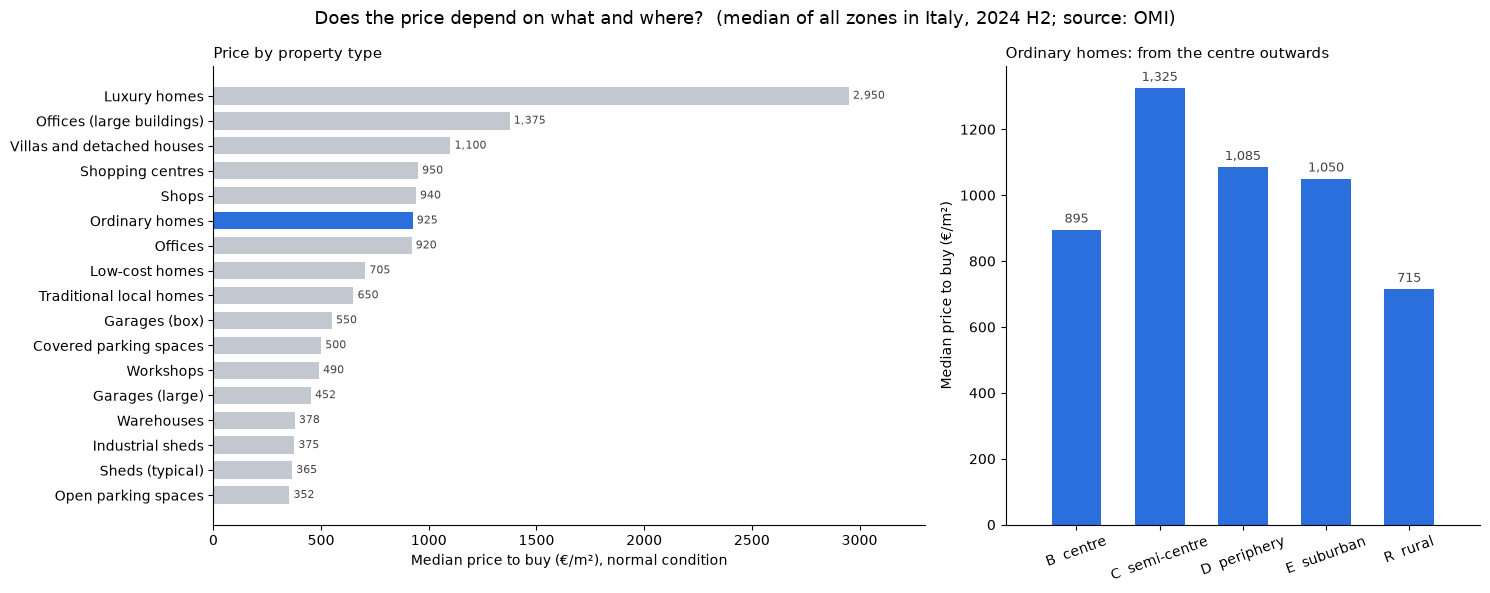

In [53]:
# Prices as numbers (the raw table is text; the decimal comma becomes a dot;
# 0 means "no quotation", so it becomes NaN)
raw_prices = valori_latest.assign(
    buy_mid=lambda d: (
        pd.to_numeric(d["Compr_min"].str.replace(",", "."), errors="coerce")
        + pd.to_numeric(d["Compr_max"].str.replace(",", "."), errors="coerce")
    ) / 2
)
raw_prices.loc[raw_prices["buy_mid"] <= 0, "buy_mid"] = np.nan

# Median price per property type (normal condition only, to compare like with like)
by_type = (raw_prices[raw_prices[STATE_COL] == "NORMALE"]
           .groupby(TYPE_COL)["buy_mid"].median().sort_values())

# Median price of ordinary homes per position in the comune
homes_normal = raw_prices[(raw_prices[TYPE_COL] == "Abitazioni civili")
                          & (raw_prices[STATE_COL] == "NORMALE")]
by_fascia = homes_normal.groupby(FASCIA_COL)["buy_mid"].median().reindex(FASCIA_ORDER)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [3, 2]})

colors = [KEPT_COLOR if name == "Abitazioni civili" else OTHER_COLOR for name in by_type.index]
bars = axes[0].barh([TYPE_LABELS.get(n, n) for n in by_type.index], by_type.values,
                    color=colors, height=0.7)
axes[0].bar_label(bars, fmt="{:,.0f}", padding=3, fontsize=8, color="#444")
axes[0].set_xlabel("Median price to buy (€/m²), normal condition")
axes[0].set_title("Price by property type", loc="left", fontsize=11)

bars = axes[1].bar([FASCIA_LABELS[f] for f in FASCIA_ORDER], by_fascia.values,
                   color=KEPT_COLOR, width=0.6)
axes[1].bar_label(bars, fmt="{:,.0f}", padding=3, fontsize=9, color="#444")
axes[1].set_ylabel("Median price to buy (€/m²)")
axes[1].set_title("Ordinary homes: from the centre outwards", loc="left", fontsize=11)
axes[1].tick_params(axis="x", rotation=20)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.margins(x=0.12)
fig.suptitle("Does the price depend on what and where?  (median of all zones in Italy, 2024 H2; source: OMI)",
             fontsize=13)
fig.tight_layout()
plt.show()

# Note: these medians mix all of Italy. The centre of a village is often cheaper than
# the periphery of Milan, so the B→R gradient here is smaller than inside one big city.

Comuni with at least one zone of each type (ordinary homes, normal condition):
Fascia
B    99.2 %
C     9.9 %
D    32.7 %
E    26.2 %
R    49.5 %
Name: Comune_ISTAT, dtype: str

Price as % of the comune's own centre (median comune):
        median %  comuni compared
Fascia                           
B          100.0             7528
C           94.0              730
D           93.0             2451
E           95.0             1975
R           83.0             3732


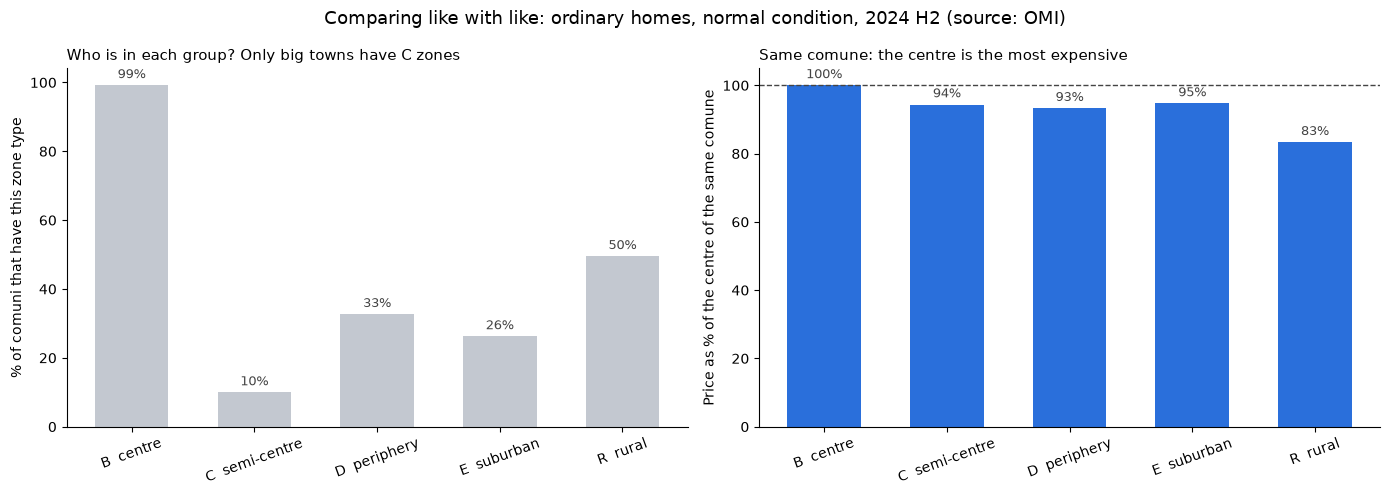

In [54]:
# 1. How many comuni have at least one zone of each type?
zones_per_fascia = homes_normal.groupby(FASCIA_COL)[CODE_COL].nunique().reindex(FASCIA_ORDER)
n_comuni_total = homes_normal[CODE_COL].nunique()
print("Comuni with at least one zone of each type (ordinary homes, normal condition):")
print((zones_per_fascia / n_comuni_total * 100).round(1).astype(str) + " %")

# 2. Median price per comune and fascia: one row per comune, one column per fascia
by_comune_fascia = (homes_normal.groupby([CODE_COL, FASCIA_COL])["buy_mid"]
                    .median()
                    .unstack()                       # fasce become columns
                    .reindex(columns=FASCIA_ORDER))

# 3. Each zone's price as a % of the centre price of the SAME comune
#    (comuni without a priced centre zone drop out: division by NaN gives NaN)
vs_centre = by_comune_fascia.div(by_comune_fascia["B"], axis=0) * 100
within = vs_centre.median().reindex(FASCIA_ORDER)    # median comune
n_pairs = vs_centre.notna().sum().reindex(FASCIA_ORDER)
print("\nPrice as % of the comune's own centre (median comune):")
print(pd.DataFrame({"median %": within.round(0), "comuni compared": n_pairs}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

bars = axes[0].bar([FASCIA_LABELS[f] for f in FASCIA_ORDER],
                   zones_per_fascia / n_comuni_total * 100, color=OTHER_COLOR, width=0.6)
axes[0].bar_label(bars, fmt="{:.0f}%", padding=3, fontsize=9, color="#444")
axes[0].set_ylabel("% of comuni that have this zone type")
axes[0].set_title("Who is in each group? Only big towns have C zones", loc="left", fontsize=11)

bars = axes[1].bar([FASCIA_LABELS[f] for f in FASCIA_ORDER], within.values,
                   color=KEPT_COLOR, width=0.6)
axes[1].bar_label(bars, fmt="{:.0f}%", padding=3, fontsize=9, color="#444")
axes[1].axhline(100, color="#444", linewidth=1, linestyle="--")
axes[1].set_ylabel("Price as % of the centre of the same comune")
axes[1].set_title("Same comune: the centre is the most expensive", loc="left", fontsize=11)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="x", rotation=20)
fig.suptitle("Comparing like with like: ordinary homes, normal condition, 2024 H2 (source: OMI)",
             fontsize=13)
fig.tight_layout()
plt.show()

In [55]:
def plot_comune_profile(name, semester_label="2024 H2"):
    """
    Price by property type and by position (fascia) for one comune.

    Parameters
    ----------
    name : str
        Comune name as written in OMI (upper case), e.g. "MILANO".
    semester_label : str, optional
        Text used in the figure title.

    Returns
    -------
    pandas.DataFrame
        Number of zones and median price per fascia, plus % of the centre price.
    """
    city = raw_prices[raw_prices[NAME_COL] == name]
    if city.empty:
        raise ValueError(f"No OMI rows for comune {name!r}: check the spelling")

    # Left panel: median price per property type (normal condition)
    city_by_type = (city[city[STATE_COL] == "NORMALE"]
                    .groupby(TYPE_COL)["buy_mid"].median().dropna().sort_values())

    # Right panel: ordinary homes, normal condition, one dot per zone
    city_homes = city[(city[TYPE_COL] == "Abitazioni civili") & (city[STATE_COL] == "NORMALE")]
    fasce = [f for f in FASCIA_ORDER if f in set(city_homes[FASCIA_COL])]
    city_by_fascia = city_homes.groupby(FASCIA_COL)["buy_mid"].agg(["count", "median"]).reindex(fasce)
    city_by_fascia["% of centre"] = (city_by_fascia["median"]
                                     / city_by_fascia.loc["B", "median"] * 100).round(0) \
        if "B" in fasce else np.nan

    fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [3, 2]})

    colors = [KEPT_COLOR if t == "Abitazioni civili" else OTHER_COLOR for t in city_by_type.index]
    bars = axes[0].barh([TYPE_LABELS.get(t, t) for t in city_by_type.index],
                        city_by_type.values, color=colors, height=0.7)
    axes[0].bar_label(bars, fmt="{:,.0f}", padding=3, fontsize=8, color="#444")
    axes[0].set_xlabel("Median price to buy (€/m²), normal condition")
    axes[0].set_title("Price by property type", loc="left", fontsize=11)
    axes[0].margins(x=0.12)

    # Median per fascia as a bar, every zone as a dot on top (shows the spread)
    x = np.arange(len(fasce))
    bars = axes[1].bar(x, city_by_fascia["median"], color=KEPT_COLOR, width=0.6, alpha=0.35)
    labels = [f"{m:,.0f}\n({p:.0f}%)" for m, p in
              zip(city_by_fascia["median"], city_by_fascia["% of centre"])]
    axes[1].bar_label(bars, labels=labels, padding=3, fontsize=9, color="#444")
    rng = np.random.default_rng(0)                     # fixed jitter = same picture every run
    for i, f in enumerate(fasce):
        zone_prices = city_homes.loc[city_homes[FASCIA_COL] == f, "buy_mid"].dropna()
        axes[1].scatter(i + rng.uniform(-0.18, 0.18, len(zone_prices)), zone_prices,
                        s=28, color=KEPT_COLOR, edgecolor="white", linewidth=0.8, zorder=3)
    axes[1].set_xticks(x, [f"{FASCIA_LABELS[f]}\n{int(n)} zones"
                           for f, n in zip(fasce, city_by_fascia["count"])])
    axes[1].set_ylabel("Price to buy (€/m²)")
    axes[1].set_title("Ordinary homes: one dot per OMI zone, bar = median",
                      loc="left", fontsize=11)
    axes[1].set_ylim(0, city_homes["buy_mid"].max() * 1.15)

    for ax in axes:
        ax.spines[["top", "right"]].set_visible(False)
    fig.suptitle(f"{name.title()}: what and where, {semester_label} (source: OMI)", fontsize=13)
    fig.tight_layout()
    plt.show()
    return city_by_fascia

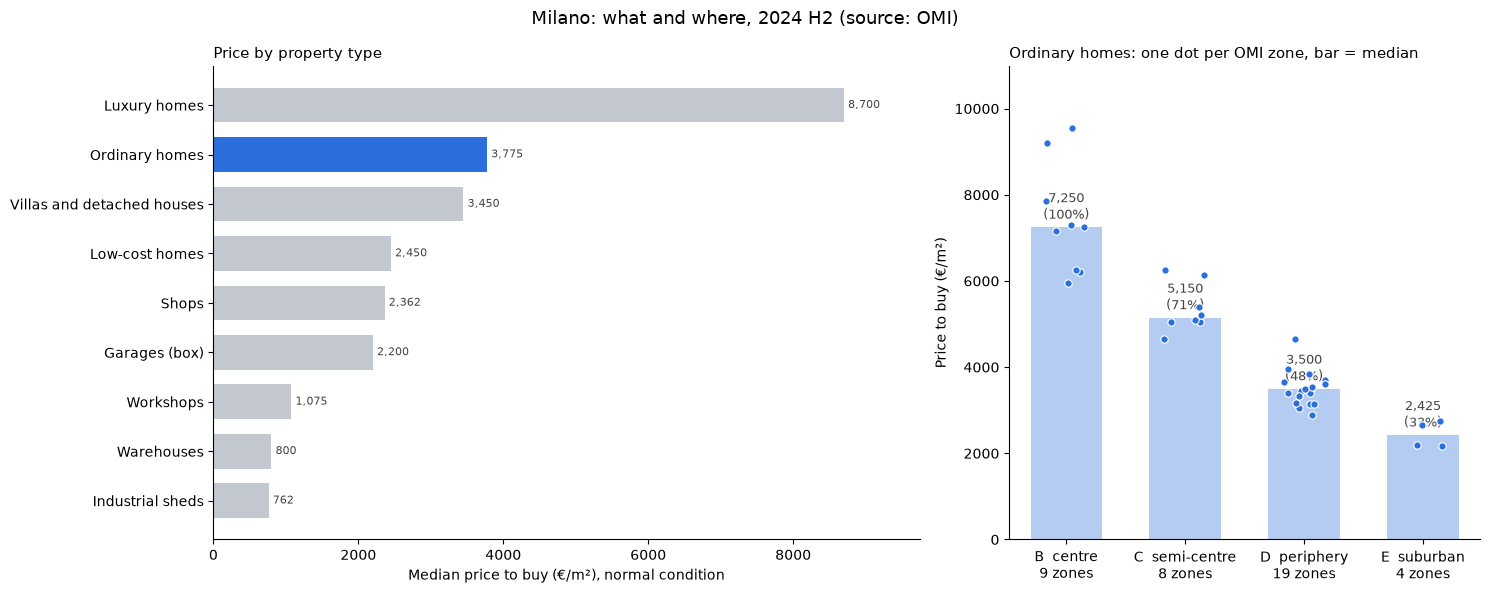

,count,median,% of centre
Fascia,,,
B,9,7250.0,100.0
C,8,5150.0,71.0
D,19,3500.0,48.0
E,4,2425.0,33.0


In [56]:
milan_profile = plot_comune_profile("MILANO")
milan_profile

In [57]:
# CHECK: what do the ISTAT codes look like? (MEF uses 6 digits as text: "015146")
print(valori_latest[CODE_COL].str.len().value_counts(dropna=False))
print(valori_latest[CODE_COL].head().tolist())

# CHECK: the unusual ones (missing, 5 or 6 digits): which comuni are they?
odd = valori_latest[valori_latest[CODE_COL].isna() | (valori_latest[CODE_COL].str.len() < 7)]
print(odd[[REGION_COL, "Prov", CODE_COL, NAME_COL]].drop_duplicates().to_string())

Comune_ISTAT
7.0    87601
8.0    69836
6.0      179
5.0       68
NaN        1
Name: count, dtype: int64
['1006003', '1006003', '1006003', '1006003', '1006003']
               Regione Prov Comune_ISTAT     Comune_descrizione
2112          PIEMONTE   AL        16191        CASSANO SPINOLA
3326          PIEMONTE   AT       105122     MORANSENGO-TONENGO
4080          PIEMONTE   BI       196085                LESSONA
4119          PIEMONTE   BI       196088              VALDILANA
12872         PIEMONTE   TO        11317             VAL DI CHY
12884         PIEMONTE   TO        11318              VALCHIUSA
27173        LOMBARDIA   CR       319116       PIADENA DRIZZONA
33989        LOMBARDIA   MI       315251      VERMEZZO CON ZELO
41432        LOMBARDIA   VA       312143  CADREZZATE CON OSMATE
65009           VENETO   VI       524124      BARBARANO MOSSANO
73921   EMILIA-ROMAGNA   FE        38028         TERRE DEL RENO
73956   EMILIA-ROMAGNA   FE       838030             TRESIGNANA
73974   

## 4. From zones to one price per comune

Steps:
1. **Clean the numbers**: text → float (a comma decimal becomes a dot).
2. **Clean the code**: OMI puts the region number in front (`1006003`), so we keep
   the last 6 digits (`006003` = Alessandria), the same format as MEF.
3. **Filter**: only ordinary homes (*Abitazioni civili*) in normal condition
   (*NORMALE*), so we compare the same kind of property everywhere.
4. **Zone midpoint** = (min + max) / 2.
5. **Comune price** = **median** of its zone midpoints. The median is not pulled up
   by one luxury zone in the centre.

In [34]:
def clean_omi_values(df, semester):
    """
    Turn a raw OMI VALORI table into clean numbers for ordinary homes.

    Parameters
    ----------
    df : pandas.DataFrame
        A VALORI table as returned by ``read_omi_csv``.
    semester : str
        For example ``"2024_2"``; stored in a ``semester`` column and a ``year`` column.

    Returns
    -------
    pandas.DataFrame
        Only "Abitazioni civili" in "NORMALE" condition, with numeric prices,
        a 6-digit text ``istat_code`` and the zone midpoints ``buy_mid``, ``rent_mid``.
    """
    df = df.copy()
    for col in PRICE_COLS:
        # "1.234,5" style is not expected, but a decimal comma is possible
        df[col] = pd.to_numeric(df[col].str.replace(",", ".", regex=False), errors="coerce")
        # A price of 0 means "no quotation" (e.g. the 2016 earthquake zones of Norcia,
        # Arquata del Tronto...), not a free house: treat it as missing
        df.loc[df[col] <= 0, col] = np.nan

    # OMI writes the region number in front of the 6-digit ISTAT code:
    # "1006003" = region 1 (Piemonte) + "006003" (Alessandria).
    # \D = any non-digit: remove it, then keep the LAST 6 digits.
    # A few codes are shorter (5-6 digits): zfill(6) pads them with zeros on the left.
    df["istat_code"] = df[CODE_COL].str.replace(r"\D", "", regex=True).str[-6:].str.zfill(6)

    homes = df[
        (df[TYPE_COL].str.strip().str.lower() == "abitazioni civili")
        & (df[STATE_COL].str.strip().str.upper() == "NORMALE")
    ].copy()

    homes["buy_mid"] = (homes["Compr_min"] + homes["Compr_max"]) / 2
    homes["rent_mid"] = (homes["Loc_min"] + homes["Loc_max"]) / 2
    homes["semester"] = semester
    homes["year"] = int(semester[:4])
    return homes


homes = pd.concat(
    [clean_omi_values(tables["VALORI"], sem) for sem, tables in raw.items()],
    ignore_index=True,
)
print(homes.groupby("semester").size().rename("zones with ordinary homes"))

semester
2014_2    20384
2024_2    20678
Name: zones with ordinary homes, dtype: int64


In [35]:
# CHECK: data quality
print("Missing prices:\n", homes[["buy_mid", "rent_mid"]].isna().sum(), sep="")
print("Zones where min > max:", (homes["Compr_min"] > homes["Compr_max"]).sum())
print("Comuni with no quotation at all (all zones missing):")
no_price = homes.groupby(["semester", "istat_code", NAME_COL])["buy_mid"].count()
print(no_price[no_price == 0].reset_index()[["semester", NAME_COL]].to_string())
print("\nZone prices (€/m²):")
print(homes.groupby("semester")["buy_mid"].describe().round(0))

Missing prices:
buy_mid       93
rent_mid    3113
dtype: int64
Zones where min > max: 0
Comuni with no quotation at all (all zones missing):
   semester       Comune_descrizione
0    2014_2                 BOMPORTO
1    2014_2               CAMPOSANTO
2    2014_2                  CAVEZZO
3    2014_2  CONCORDIA SULLA SECCHIA
4    2014_2            FINALE EMILIA
5    2014_2                  MEDOLLA
6    2014_2                MIRANDOLA
7    2014_2           NOVI DI MODENA
8    2014_2                 RAVARINO
9    2014_2    SAN FELICE SUL PANARO
10   2014_2           SAN POSSIDONIO
11   2014_2             SAN PROSPERO
12   2014_2                  SOLIERA
13   2014_2                GIBELLINA
14   2024_2       ARQUATA DEL TRONTO
15   2024_2               MONTEGALLO
16   2024_2                   CASCIA
17   2024_2       CERRETO DI SPOLETO
18   2024_2    MONTELEONE DI SPOLETO
19   2024_2                   NORCIA
20   2024_2               POGGIODOMO
21   2024_2                    PRECI
22   202

In [36]:
def comune_prices(homes):
    """
    One row per comune and semester, with the median zone price and rent.

    Parameters
    ----------
    homes : pandas.DataFrame
        Output of ``clean_omi_values`` (one row per zone).

    Returns
    -------
    pandas.DataFrame
        Columns ``istat_code``, ``semester``, ``year``, ``comune``, ``region``,
        ``n_zones``, ``buy_m2`` (median €/m²), ``rent_m2`` (median €/m² per month).
    """
    return (
        homes.groupby(["istat_code", "semester", "year"], as_index=False)
        .agg(
            comune=(NAME_COL, "first"),
            region=(REGION_COL, "first"),
            n_zones=(ZONE_COL, "nunique"),
            buy_m2=("buy_mid", "median"),
            rent_m2=("rent_mid", "median"),
        )
    )


prices = comune_prices(homes)
print(prices.groupby("semester").size().rename("comuni"))
print("\nCHECK: Milan should be a few thousand €/m²")
print(prices[prices["istat_code"] == MILAN_CODE].to_string())

semester
2014_2    7681
2024_2    7613
Name: comuni, dtype: int64

CHECK: Milan should be a few thousand €/m²
     istat_code semester  year  comune     region  n_zones  buy_m2  rent_m2
3600     015146   2014_2  2014  MILANO  LOMBARDIA       38  2550.0    8.000
3601     015146   2024_2  2024  MILANO  LOMBARDIA       40  3775.0   12.725


## 5. Insights

### 5.1 Where are homes expensive?

In [37]:
latest = prices[prices["semester"] == "2024_2"]

print("Most expensive comuni (median €/m², 2024 H2):")
print(latest.nlargest(15, "buy_m2")[["comune", "region", "n_zones", "buy_m2", "rent_m2"]].to_string())
print("\nCheapest comuni:")
print(latest.nsmallest(10, "buy_m2")[["comune", "region", "n_zones", "buy_m2", "rent_m2"]].to_string())

Most expensive comuni (median €/m², 2024 H2):
                                              comune                         region  n_zones   buy_m2  rent_m2
2535                                       PORTOFINO                        LIGURIA        3  11250.0   25.150
6370                               CORTINA D`AMPEZZO                         VENETO        4   8475.0   19.575
10154                                          CAPRI                       CAMPANIA        4   7775.0   18.125
3306                                         LIVIGNO                      LOMBARDIA        5   6550.0   13.550
2074                                      COURMAYEUR  VALLE D'AOSTA/VALLE`E D'AOSTE        5   6350.0   12.050
10134                                       ANACAPRI                       CAMPANIA        2   6100.0   14.250
5517                          ORTISEI .SANKT ULRICH.            TRENTINO-ALTO ADIGE        4   5400.0   17.175
5571   SELVA DI VAL GARDENA .WOLKENSTEIN IN GROEDEN.            TR

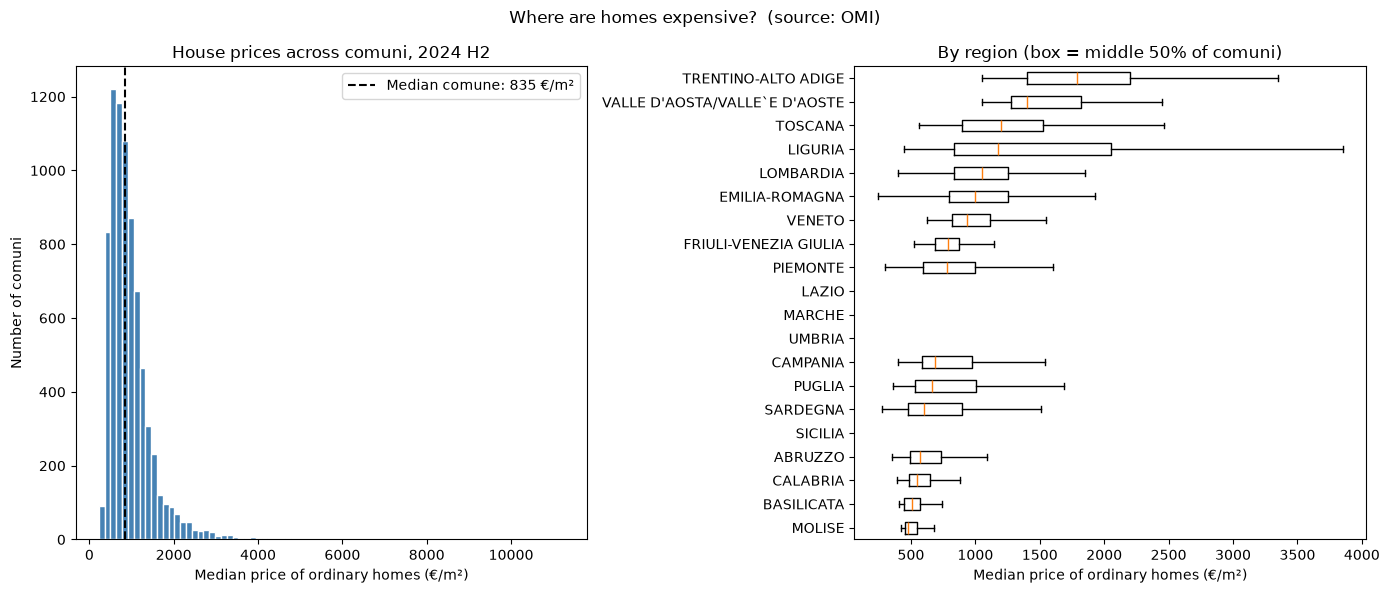

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].hist(latest["buy_m2"], bins=80, color="steelblue", edgecolor="white")
axes[0].axvline(latest["buy_m2"].median(), color="black", linestyle="--",
                label=f"Median comune: {latest['buy_m2'].median():,.0f} €/m²")
axes[0].set_xlabel("Median price of ordinary homes (€/m²)")
axes[0].set_ylabel("Number of comuni")
axes[0].set_title("House prices across comuni, 2024 H2")
axes[0].legend()

# Regions sorted by their median comune price
order = latest.groupby("region")["buy_m2"].median().sort_values().index
data = [latest.loc[latest["region"] == region, "buy_m2"] for region in order]
axes[1].boxplot(data, orientation="horizontal", showfliers=False)
axes[1].set_yticks(range(1, len(order) + 1), order)
axes[1].set_xlabel("Median price of ordinary homes (€/m²)")
axes[1].set_title("By region (box = middle 50% of comuni)")

fig.suptitle("Where are homes expensive?  (source: OMI)")
fig.tight_layout()
plt.show()

### 5.2 Centre vs periphery
How much more does a m² cost in the **centre** (fascia B) than in the
**periphery** (fascia D)? A high ratio means a very unequal city: living
centrally is a privilege. Only comuni that have both kinds of zone.

In [39]:
def centre_premium(homes, semester):
    """
    Ratio between the centre (B) and periphery (D) price for every comune.

    Parameters
    ----------
    homes : pandas.DataFrame
        Output of ``clean_omi_values``.
    semester : str
        The semester to use, e.g. ``"2024_2"``.

    Returns
    -------
    pandas.DataFrame
        One row per comune that has both B and D zones: ``centre``,
        ``periphery`` (median €/m²) and ``premium`` (centre / periphery).
    """
    data = homes[(homes["semester"] == semester) & homes[FASCIA_COL].isin(["B", "D"])]
    # pivot_table: one row per comune, one column per fascia, median price inside
    table = data.pivot_table(index=["istat_code", NAME_COL], columns=FASCIA_COL,
                             values="buy_mid", aggfunc="median").dropna()
    table = table.rename(columns={"B": "centre", "D": "periphery"})
    table["premium"] = table["centre"] / table["periphery"]
    return table.reset_index()


premium = centre_premium(homes, "2024_2")
print(f"{len(premium)} comuni have both centre and periphery zones")
print(premium["premium"].describe().round(2))
print("\nCities where the centre costs the most compared with the periphery:")
print(premium.nlargest(15, "premium").round(2).to_string())

2451 comuni have both centre and periphery zones
count    2451.00
mean        1.09
std         0.20
min         0.52
25%         0.97
50%         1.07
75%         1.18
max         3.13
Name: premium, dtype: float64

Cities where the centre costs the most compared with the periphery:
Fascia istat_code Comune_descrizione  centre  periphery  premium
1650       065100           POSITANO  7200.0     2300.0     3.13
1633       065044   CONCA DEI MARINI  3700.0     1600.0     2.31
846        028060             PADOVA  2787.5     1237.5     2.25
1115       046013     FORTE DE MARMI  7000.0     3275.0     2.14
1676       067025         GIULIANOVA  2175.0     1025.0     2.12
1984       079137           SOVERATO  1650.0      785.0     2.10
520        015146             MILANO  7250.0     3500.0     2.07
1639       065066             MAIORI  4250.0     2075.0     2.05
1202       054001             ASSISI  1837.5      900.0     2.04
902        030117           TARVISIO  1575.0      787.5     2.00
1

### 5.3 Prices 2014 → 2024
Prices are **nominal**: consumer prices in Italy rose by roughly 20% in this period
(CHECK the exact value on ISTAT's "Rivaluta" calculator), so a comune where prices
rose less than that got **cheaper in real terms**.

In [40]:
INFLATION_2014_2024 = 0.20   # approximate; replace with the ISTAT value

wide = prices.pivot_table(index="istat_code", columns="year", values="buy_m2")
wide = wide.dropna()        # only comuni with a price in both years (same code)
wide["change_pct"] = (wide[2024] / wide[2014] - 1) * 100
wide = wide.join(latest.set_index("istat_code")[["comune", "region"]])

print(f"Comuni in both semesters: {len(wide)}")
print(wide["change_pct"].describe().round(1))
print(f"\nShare of comuni where prices fell (nominal): {(wide['change_pct'] < 0).mean():.0%}")
# OMI does not revise every zone every semester: in many small comuni the
# quotation is simply unchanged after 10 years. That is a limitation, not a market.
print(f"Share with EXACTLY the same price as in 2014: {(wide['change_pct'] == 0).mean():.0%}")
print(f"Share where they rose more than inflation: {(wide['change_pct'] > INFLATION_2014_2024 * 100).mean():.0%}")

by_region = wide.groupby("region")["change_pct"].median().sort_values()
print("\nMedian change by region (%):")
print(by_region.round(1))

Comuni in both semesters: 7333
count    7333.0
mean       -6.2
std        14.4
min       -52.0
25%       -15.8
50%        -4.9
75%         0.0
max       142.6
Name: change_pct, dtype: float64

Share of comuni where prices fell (nominal): 66%
Share with EXACTLY the same price as in 2014: 11%
Share where they rose more than inflation: 4%

Median change by region (%):
region
UMBRIA                          -25.0
LAZIO                           -21.2
SICILIA                         -16.6
ABRUZZO                         -16.4
TOSCANA                         -15.1
PIEMONTE                        -13.1
BASILICATA                      -11.5
MARCHE                          -10.1
PUGLIA                           -8.9
CAMPANIA                         -7.6
VALLE D'AOSTA/VALLE`E D'AOSTE    -7.3
EMILIA-ROMAGNA                   -6.1
CALABRIA                         -5.8
LIGURIA                          -4.8
VENETO                           -4.3
LOMBARDIA                         0.0
MOLISE           

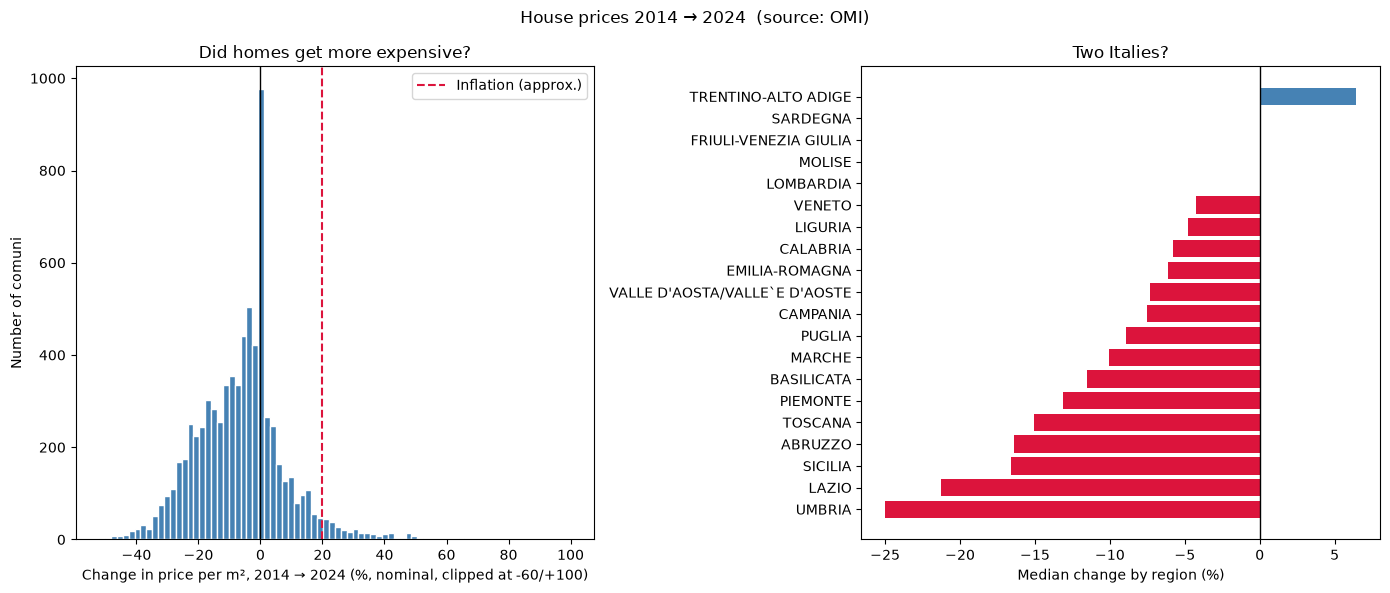

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].hist(wide["change_pct"].clip(-60, 100), bins=80, color="steelblue", edgecolor="white")
axes[0].axvline(0, color="black", linewidth=1)
axes[0].axvline(INFLATION_2014_2024 * 100, color="crimson", linestyle="--", label="Inflation (approx.)")
axes[0].set_xlabel("Change in price per m², 2014 → 2024 (%, nominal, clipped at -60/+100)")
axes[0].set_ylabel("Number of comuni")
axes[0].set_title("Did homes get more expensive?")
axes[0].legend()

axes[1].barh(by_region.index, by_region.values,
             color=["crimson" if v < 0 else "steelblue" for v in by_region.values])
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_xlabel("Median change by region (%)")
axes[1].set_title("Two Italies?")

fig.suptitle("House prices 2014 → 2024  (source: OMI)")
fig.tight_layout()
plt.show()

### 5.4 Buy or rent?
- **Gross rental yield** = yearly rent / price. What a landlord earns per year,
  before taxes and costs. High yield = buying to rent out pays.
- **Price-to-rent ratio** = price / yearly rent = how many years of rent a home costs.
  Low ratio = buying is cheap compared with renting.

       rental_yield  price_to_rent
count      7101.000       7101.000
mean          0.046         22.734
std           0.010          4.771
min           0.016         10.417
25%           0.040         19.727
50%           0.045         22.337
75%           0.051         25.085
max           0.096         61.012


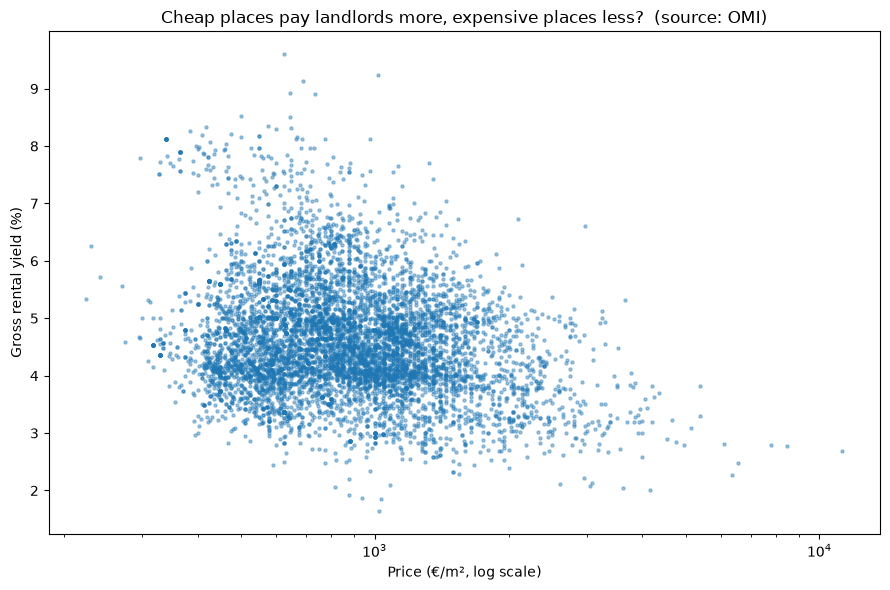

In [42]:
latest = latest.assign(
    rental_yield=latest["rent_m2"] * 12 / latest["buy_m2"],
    price_to_rent=latest["buy_m2"] / (latest["rent_m2"] * 12),
)
print(latest[["rental_yield", "price_to_rent"]].describe().round(3))

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(latest["buy_m2"], latest["rental_yield"] * 100, s=5, alpha=0.4)
ax.set_xscale("log")   # prices span from a few hundred to over 10,000 €/m²
ax.set_xlabel("Price (€/m², log scale)")
ax.set_ylabel("Gross rental yield (%)")
ax.set_title("Cheap places pay landlords more, expensive places less?  (source: OMI)")
fig.tight_layout()
plt.show()

**Did renting get more expensive faster than buying?** Same comuni, both years.

In [43]:
rent_wide = prices.pivot_table(index="istat_code", columns="year", values="rent_m2").dropna()
both_changes = pd.DataFrame({
    "buy_change": wide["change_pct"],
    "rent_change": (rent_wide[2024] / rent_wide[2014] - 1) * 100,
}).dropna()
print(both_changes.describe().round(1))
print(f"\nComuni where rents rose faster than prices: {(both_changes['rent_change'] > both_changes['buy_change']).mean():.0%}")

       buy_change  rent_change
count      6921.0       6921.0
mean         -6.1          1.6
std          14.3         18.5
min         -51.6        -63.1
25%         -15.6         -8.1
50%          -5.0          0.0
75%           0.0          7.1
max         142.6        157.8

Comuni where rents rose faster than prices: 67%


### 5.5 First look at the main question
Join the 2024 prices with the MEF 2024 incomes on the ISTAT code and compute:
- **years of taxable income** to buy a 70 m² flat;
- **years of an employee's wage** for the same flat.

This is only a preview: the proper merge (with code harmonisation and checks) comes
in Week 3, in the `affordability` package.

In [44]:
mef = pd.read_csv(
    mef_raw_dir / "mef_income_2024.csv",
    sep=";", encoding="latin-1", dtype={"Codice Istat Comune": str},
    keep_default_na=False, na_values=[""],
)
mef.columns = [" ".join(col.split()).replace("- Ammontare in euro", "- Ammontare") for col in mef.columns]
income = pd.DataFrame({
    "istat_code": mef["Codice Istat Comune"],
    "taxpayers": mef["Numero contribuenti"],
    "mean_income": mef["Reddito imponibile - Ammontare"] / mef["Reddito imponibile - Frequenza"],
    "mean_wage": mef["Reddito da lavoro dipendente e assimilati - Ammontare"]
                 / mef["Reddito da lavoro dipendente e assimilati - Frequenza"],
})

# how="inner": keep only comuni present in both; validate checks one row per code on each side
afford = latest.merge(income, on="istat_code", how="inner", validate="one_to_one")
print(f"OMI comuni: {len(latest)}, MEF comuni: {len(income)}, matched: {len(afford)}")

afford["flat_price"] = afford["buy_m2"] * FLAT_SIZE_M2
afford["years_income"] = afford["flat_price"] / afford["mean_income"]
afford["years_wage"] = afford["flat_price"] / afford["mean_wage"]

big = afford[afford["taxpayers"] >= MIN_TAXPAYERS]
print(big[["years_income", "years_wage"]].describe().round(1))


def weighted_median(values, weights):
    """
    Median where each value counts as many times as its weight.

    Parameters
    ----------
    values, weights : array-like
        For example years of income per comune, and taxpayers per comune.

    Returns
    -------
    float
        The value below which half of the total weight lies.
    """
    values, weights = np.asarray(values, dtype=float), np.asarray(weights, dtype=float)
    keep = ~np.isnan(values)
    values, weights = values[keep], weights[keep]
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order])
    return values[order][np.searchsorted(cumulative, cumulative[-1] / 2)]


# The describe() above treats a village of 1,000 people like Milan. Weighting by
# taxpayers answers "how many years does the TYPICAL PERSON need?"
for column in ["years_income", "years_wage"]:
    print(f"{column}: median comune = {afford[column].median():.1f}, "
          f"median person = {weighted_median(afford[column], afford['taxpayers']):.1f}")
print("\nLeast affordable (years of an employee's wage for 70 m²):")
print(big.nlargest(15, "years_wage")[["comune", "region", "buy_m2", "mean_wage", "years_income", "years_wage"]].round(1).to_string())
print("\nMilan:")
print(afford.loc[afford["istat_code"] == MILAN_CODE, ["comune", "buy_m2", "mean_income", "mean_wage", "years_income", "years_wage"]].round(1).to_string())

OMI comuni: 7613, MEF comuni: 7897, matched: 7392
       years_income  years_wage
count        4957.0      4957.0
mean            3.2         3.2
std             1.5         1.7
min             0.9         0.8
25%             2.3         2.3
50%             2.8         2.8
75%             3.5         3.6
max            17.9        22.6
years_income: median comune = 2.7, median person = 3.5
years_wage: median comune = 2.6, median person = 3.6

Least affordable (years of an employee's wage for 70 m²):
                                             comune               region  buy_m2  mean_wage  years_income  years_wage
1621                                        LIVIGNO            LOMBARDIA  6550.0    20247.3          17.9        22.6
3092                              CORTINA D`AMPEZZO               VENETO  8475.0    26896.6          17.6        22.1
4940                                          CAPRI             CAMPANIA  7775.0    25502.5          16.8        21.3
4930                   

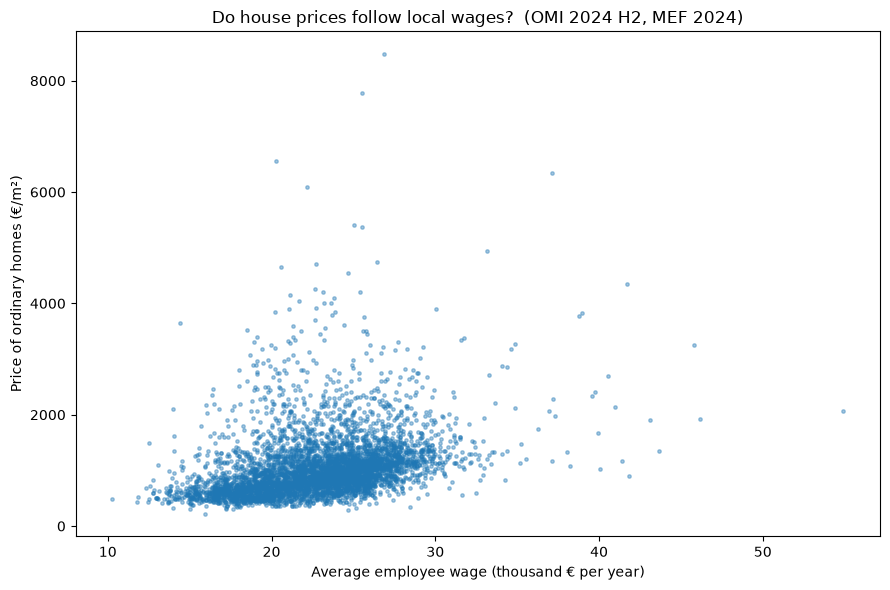

In [45]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(big["mean_wage"] / 1000, big["buy_m2"], s=6, alpha=0.4)
ax.set_xlabel("Average employee wage (thousand € per year)")
ax.set_ylabel("Price of ordinary homes (€/m²)")
ax.set_title("Do house prices follow local wages?  (OMI 2024 H2, MEF 2024)")
fig.tight_layout()
plt.show()

## Findings so far
*(Fill in after running: what surprised you? Which comuni stand out? Which numbers
need checking?)*